# **Практика 3. BeautifulSoup — извлекаем данные с веб-страниц**

**Цель:** научиться читать HTML-страницы и вытаскивать из них нужные данные.

**Когда нужен BeautifulSoup вместо RSS?**
Когда у сайта нет RSS-ленты или нужны данные с конкретной страницы — например, отзывы, рейтинги, карточки товаров.

In [1]:
!pip install requests beautifulsoup4 -q
print("Готово!")

Готово!


---
## **Часть 1: HTML и исходный код страницы**

### Исходный код веб-страницы

1) Документ, который описывает структуру, расположение элементов и логику работы веб-страницы.

2) Файлы и команды, которые отвечают за загрузку страницы, её структуру, внешний вид и поведение в браузере. В основе лежит три технологиии - HTML, CSS и JavaScript.

Для того, чтобы посмотреть исходный код любой веб-страницы чаще всего достаточно нажать правой кнопкой мыши и выбрать команду, где будет словосочетание "исходный код".

**HTML-разметка** используется в документе, который описывает структуру и наполнение веб-страницы.

**CSS** - язык для описания внешнего вида документа.

**JavaScript** - язык программирования, который используется для обработки действий пользователя и создания интерактивных элементов.

#### **HTML-разметка**

**HTML-разметка** - разметка документов, предназначенная для их отображения в браузере.

**Элемент** - структурна или визуальная часть сайта. Элемент оборачивается в html-тэг.

**Тег** — специальные ключевые слова в угловых скобках (например, \<p>), которые говорят браузеру, как отображать содержимое.

**Атрибуты** — свойства внутри открывающегося тега, которые уточняют или дополняют элемент (например, путь к картинке src="" или ссылка href="").

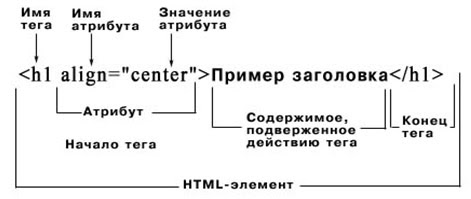

Другое определение парсинга - разбор структуры документа.

In [2]:
from bs4 import BeautifulSoup

# Пример HTML-страницы (как будто это страница новостного сайта)
html_example = """
<html>
<head><title>Новости дня</title></head>
<body>
  <div class="news-list">
    <article class="news-item">
      <h2 class="news-title">Яндекс запустил новый сервис</h2>
      <span class="news-date">15 марта 2025</span>
      <p class="news-text">Компания объявила о запуске...</p>
      <a href="/news/1" class="news-link">Читать далее</a>
    </article>
    <article class="news-item">
      <h2 class="news-title">Сбер представил обновление GigaChat</h2>
      <span class="news-date">15 марта 2025</span>
      <p class="news-text">Новая версия поддерживает...</p>
      <a href="/news/2" class="news-link">Читать далее</a>
    </article>
    <article class="news-item">
      <h2 class="news-title">VK объявил о новых функциях</h2>
      <span class="news-date">14 марта 2025</span>
      <p class="news-text">Социальная сеть добавляет...</p>
      <a href="/news/3" class="news-link">Читать далее</a>
    </article>
  </div>
</body>
</html>
"""

# Создаём объект BeautifulSoup
soup = BeautifulSoup(html_example, 'html.parser')

# Находим заголовок страницы
print("Заголовок страницы:", soup.title.text)

Заголовок страницы: Новости дня


In [3]:
# find() — находит ПЕРВЫЙ подходящий элемент

first_title = soup.find('h2', class_='news-title')
print("Первый заголовок:", first_title.text)

# find_all() — находит ВСЕ подходящие элементы

all_titles = soup.find_all('h2', class_='news-title')

print(f"\nВсе заголовки ({len(all_titles)} шт.):")
for title in all_titles:
    print(f"  - {title.text}")

Первый заголовок: Яндекс запустил новый сервис

Все заголовки (3 шт.):
  - Яндекс запустил новый сервис
  - Сбер представил обновление GigaChat
  - VK объявил о новых функциях


In [4]:
# Получаем ссылки — через атрибут href

all_links = soup.find_all('a', class_='news-link')

for link in all_links:
    print(f"Текст: {link.text} | href: {link.get('href')}")

Текст: Читать далее | href: /news/1
Текст: Читать далее | href: /news/2
Текст: Читать далее | href: /news/3


In [5]:
# Собираем всё вместе — перебираем статьи
articles = soup.find_all('article', class_='news-item')

news_data = []
for article in articles:
    item = {
        'title': article.find('h2').text.strip(),
        'date': article.find('span', class_='news-date').text.strip(),
        'text': article.find('p').text.strip()[:100],
        'link': article.find('a').get('href')
    }
    news_data.append(item)

print(f"Собрано статей: {len(news_data)}")
for item in news_data:
    print(f"\n {item['title']}")
    print(f"    {item['date']}")
    print(f"    {item['link']}")

Собрано статей: 3

 Яндекс запустил новый сервис
    15 марта 2025
    /news/1

 Сбер представил обновление GigaChat
    15 марта 2025
    /news/2

 VK объявил о новых функциях
    14 марта 2025
    /news/3


---
## **Часть 2: Парсим реальный сайт**

### Как найти нужные CSS-классы

1. Откройте нужный сайт в браузере
2. Нажмите правой кнопкой на нужный элемент → «Просмотр кода» или F12
3. В коде найдите `class="..."` — это имя класса

Попробуем с сайтом «Хабр» (habr.com) — он обычно доступен.

In [6]:
import requests
from bs4 import BeautifulSoup
import time

def get_page(url):
    """Безопасно получает HTML страницы."""
    headers = {
        # Представляемся браузером, а не ботом
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'
    }
    try:
        response = requests.get(url, headers=headers, timeout=10)
        if response.status_code == 200:
            return response.text
        else:
            print(f"Ошибка: статус {response.status_code}")
            return None
    except Exception as e:
        print(f"Ошибка соединения: {e}")
        return None

In [7]:
html = get_page("https://www.cnews.ru/news")

if html:
    soup = BeautifulSoup(html, 'html.parser')

    articles = soup.find_all('div', class_='allnews_item')
    print(f"Найдено статей: {len(articles)}")

    for article in articles[:5]:
        # Ищем заголовок — может быть h2 или a с определённым классом
        title_tag = article.find('a')
        if title_tag:
            print(f" {title_tag.text.strip()[:80]}")
else:
    print("Не удалось получить страницу")

Найдено статей: 60
 DDoS-Guard запустила аналог капчи Google и Cloudflare
 Ozon запустил режим «Лайкзон»
 Wildberries запускает первый этап новой программы лояльности
 Билайн запустил бесплатный мультиязычный ИИ-сервис beeGPT для всех клиентов
 «Игроник» и «Солар» завершили проект по защите данных


---
## **Часть 3: Практический проект — мониторинг упоминаний**

In [8]:
# Устанавливаем нужные библиотеки
!pip install requests feedparser -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.7/80.7 kB 831.8 kB/s eta 0:00:00


In [9]:
def parse_rss_source(source_config, keywords):
    """Парсит RSS-источник."""
    import feedparser
    feed = feedparser.parse(source_config['url'])
    results = []

    for entry in feed.entries:
        text = (entry.get('title', '') + ' ' + entry.get('summary', '')).lower()
        for kw in keywords:
            if kw.lower() in text:
                results.append({
                    'source': source_config['name'],
                    'title': entry.get('title', ''),
                    'date': entry.get('published', ''),
                    'link': entry.get('link', ''),
                    'summary': entry.get('summary', '')[:200],
                    'keyword': kw,
                    'collected_at': datetime.now().strftime('%Y-%m-%d %H:%M')
                })
                break
    return results

---
## Самостоятельное задание

**Кейс:** Вы — PR-менеджер стартапа в сфере EdTech.
Создайте систему мониторинга, которая:
1. Собирает новости с разных html-страниц и RSS-лент. Источники уже перечислены в списке `SOURCES`.
2. Ищет упоминания **трёх ключевых слов** (выберите одну из тематик: образование, технологии, EdTech, ИИ) в **заголовках статей** для html-источника и в **заголовке и кратком содержании** для RSS-лент (функция для работы с RSS-лентами уже есть, см. выше).
3. Для некоторых источников не указан тег, где содержится заголовок — заполните эти поля самостоятельно (они помечены комментарием `# вставить тэг`)
4. Сохраняет в CSV с колонками: источник, заголовок.
Колонок может быть больше.

Этап 1. Поймите, в каких html-элементах лежит нужная вам информация (заголовок статьи). При необходимости можете добавить новые поля или удалить старые, но тогда исправьте соответствующим образом функцию из этапа 3.

In [10]:
SOURCES = [
           {
            'name': 'N+1',
            'type': 'rss',
            'url': 'https://nplus1.ru/rss',
           },
           {
            'name': 'proglib',
            'type': 'html',
            'url': 'https://proglib.io/',
            'article_tag': 'article', # вставить тэг (замените пустую строку на тэг)
            'class_attr_article': 'preview-card', # вставить атрибут (замените пустую строку на тэг)
            'title_tag': 'h2', # вставить тэг (замените пустую строку на тэг),
            'class_attr_title':'preview-card__title' # вставить тэг (замените пустую строку на тэг),
           }
]

Этап 2. Замените ключевые слова ниже на свои.

In [27]:
KEYWORDS = ['университет', 'студент', 'образование']

Этап 3. Допишите функцию ниже (опирайтесь на код из части 2). Обратите внимание, что каждую статью вам нужно сохранить как словарь, а затем получившийся словарь добавить в список `results`. За образец можете взять словарь из функции `parse_rss_source`. Не забудьте добавить фильтрацию по ключевым словам.

Словарь должен выглядеть так (но можно добавить еще поля):

```python
{'source' : source,
'title' : title_tag.text.strip()}
```


In [28]:
def parse_html_source(HTML_SOURCE, KEYWORDS):
  results = []

  # здесь можно что-то убрать
  source = HTML_SOURCE['url']
  article_tag = HTML_SOURCE['article_tag']
  title_tag = HTML_SOURCE['title_tag']
  class_attr_article = HTML_SOURCE['class_attr_article']
  class_attr_title = HTML_SOURCE['class_attr_title']

  html = get_page(source)

  # ваш код здесь
  # не забудьте добавить фильтрацию по ключевым словам
  if not html:
      return results

  soup = BeautifulSoup(html, 'html.parser')
  articles = soup.find_all(article_tag, class_=class_attr_article)

  for article in articles:
      title_el = article.find(title_tag, class_=class_attr_title)
      if not title_el:
          continue

      title_text = title_el.text.strip()

      for kw in KEYWORDS:
          if kw.lower() in title_text.lower():
              results.append({
                  'source': HTML_SOURCE['name'],
                  'title': title_text
              })
              break


  return results # это должен быть список словарей

Этап 3. Присвойте значение переменной results в блоке с `else`, примерно так:
```python
results = []
```
надо заменить на:
```python
results = parse_html_source(source['url'], KEYWORDS)
```
или
```python
results = parse_html_source(source, KEYWORDS)
```
в зависимости от вашей реализации

In [29]:
# Запускаем мониторинг
all_results = []

for source in SOURCES:
    print(f"\nОбрабатываю: {source['name']}...")

    if source['type'] == 'rss':
        results = parse_rss_source(source, KEYWORDS)
    else:
        results = parse_html_source(source, KEYWORDS)

    print(f"  Найдено упоминаний: {len(results)}")
    all_results.extend(results)
    time.sleep(1)

print(f"\nИТОГО: {len(all_results)} упоминаний")


Обрабатываю: N+1...
  Найдено упоминаний: 0

Обрабатываю: proglib...
  Найдено упоминаний: 1

ИТОГО: 1 упоминаний


In [30]:
from datetime import datetime
import csv

In [20]:
# Сохраняем в csv
if all_results:
    filename = f"monitoring_{datetime.now().strftime('%Y%m%d_%H%M')}.csv"
    with open(filename, 'w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=all_results[0].keys())
        writer.writeheader()
        writer.writerows(all_results)
    print(f" Сохранено в: {filename}")

    from google.colab import files
    files.download(filename)

 Сохранено в: monitoring_20260915_1449.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Запустите получившийся код.

Не забудьте дать доступ к тетрадке. Если использовали ИИ, например, для поиска тэга в исходном коде страницы, напишите об этом.

При выполнении задания использовался ИИ для подсказки HTML-тегов и классов карточек статей на proglib.io